# Run Neural Cello yourself

Everything below runs from the weights in `models/` (about 125 MB, already in the repo). A GPU makes it fast; a CPU works too
(about 30 s to perform a minute of music).

1. **Compose** a new melody in a chosen key, meter and style.
2. **Perform** it: notes → expressive pitch and loudness curves → the codec's latent → audio.
3. **Reconstruct** a real recording through the 24-number-per-frame code.
4. **Edit** the recording through the latent: loudness, then volume and bowing effort separately.

In [1]:
# In Colab or a fresh environment, uncomment:
# !git clone https://github.com/quinnbrighton/neural-cello && %cd neural-cello
# !pip install -q -r requirements.txt
import numpy as np, soundfile as sf, matplotlib.pyplot as plt
from IPython.display import Audio, display
import neuralcello as nc
m = nc.load()                                      # CUDA if available, else CPU; models load on first use
SR = nc.SR                                         # 24 kHz

## 1. Compose
Styles: `folk`, `chorale`, `cello` (Bach-suite style). `tau` is the target surprise per token: lower is more predictable.

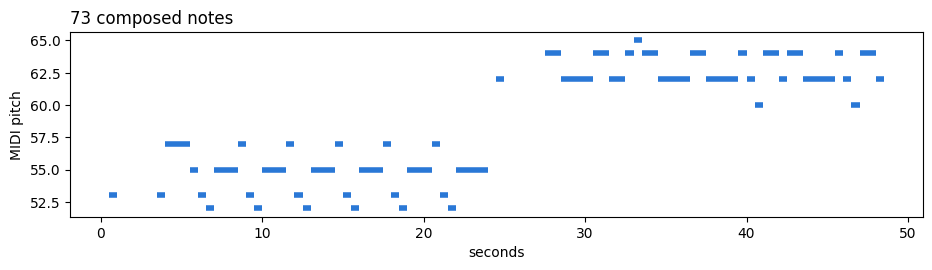

In [2]:
midi = m.compose(style="folk", key="D minor", meter="3/4", bars=16, bpm=60, tau=0.6, seed=0)
notes = midi.instruments[0].notes
plt.figure(figsize=(11, 2.4))
for n in notes: plt.plot([n.start, n.end], [n.pitch, n.pitch], lw=4, color="#2a78d6", solid_capstyle="butt")
plt.xlabel("seconds"); plt.ylabel("MIDI pitch"); plt.title(f"{len(notes)} composed notes", loc="left"); plt.show()

## 2. Perform
The notes go through the performance model (slides, vibrato, dynamics), the latent model and the decoder.

In [3]:
audio = m.perform(midi, vib=0.6, seed=0)
sf.write("my_piece.wav", audio, SR)
display(Audio(audio, rate=SR))

## 3. Reconstruct a recording
The held-out Maisky clip is encoded to 24 numbers every 40 ms and decoded again.

12 s of audio -> latent of shape (300, 24) (7200 numbers instead of 288000)


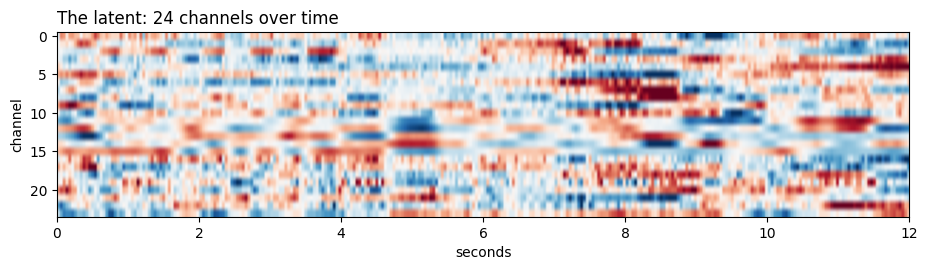

In [4]:
x, sr = sf.read("docs/assets/audio/1_original_maisky.wav")
z = m.encode(x, sr)                                # (frames, 24) at 25 Hz
y = m.decode(z)
print(f"{len(x) / sr:.0f} s of audio -> latent of shape {z.shape} ({z.size} numbers instead of {len(x)})")
display(Audio(x, rate=sr), Audio(y, rate=SR))
plt.figure(figsize=(11, 2.4)); plt.imshow(((z - z.mean(0)) / z.std(0)).T, aspect="auto", cmap="RdBu_r", vmin=-2.5, vmax=2.5, extent=[0, len(z) / 25, 23.5, -0.5])
plt.xlabel("seconds"); plt.ylabel("channel"); plt.title("The latent: 24 channels over time", loc="left"); plt.show()

## 4. Edit through the latent
`models/loudness_direction.npy` is the direction in the latent along which loudness changes (fitted within recordings, after removing
pitch). Pushing along it and then turning the result back down to the same level leaves only the change in *how* the cello is played:
more upper harmonics, a more sustained, scratchier tone.

In [5]:
d = np.load("models/loudness_direction.npy")
pushed = m.decode(z + 20 * d)
rms = lambda v: np.sqrt(np.mean(v ** 2))
print(f"the push raised the level by {20 * np.log10(rms(pushed) / rms(y)):.1f} dB; both clips below are played at the same level")
pushed = pushed / rms(pushed) * rms(y)
display(Audio(y, rate=SR), Audio(pushed, rate=SR))

the push raised the level by 7.7 dB; both clips below are played at the same level


The loudness direction mixes two controls, which the repo also ships separately: a pure **volume** axis
(`models/gain_direction.npy`, latent change per dB) and an **effort** axis (`models/tone_direction.npy`, how hard the bow digs in,
at almost constant level). Try them on their own:

In [6]:
vol, effort = np.load("models/gain_direction.npy"), np.load("models/tone_direction.npy")
louder = m.decode(z + 6 * vol)                     # about 6 dB on the encoder's volume axis: louder, same playing
harder = m.decode(z + 60 * effort); harder = harder / rms(harder) * rms(y)   # heavier bow at the same level
softer = m.decode(z - 60 * effort); softer = softer / rms(softer) * rms(y)   # lighter bow, darker tone
display(Audio(louder, rate=SR), Audio(harder, rate=SR), Audio(softer, rate=SR))

## Also from the command line
```bash
python -m neuralcello compose piece.wav --style folk --key "D minor" --meter 3/4 --bars 24   # writes piece.mid and piece.wav
python -m neuralcello perform piece.mid piece.wav
python -m neuralcello reconstruct input.wav output.wav
```